# EDA: датасет T-ECD (домен Marketplace)

**Данные:** `t-tech/T-ECD` — события маркетплейса T-Банка (small-версия), ~130 млн событий за 227 дней.

**Терминология:** в дальнейших задачах `seen` = `view` (карточка показана), `tap` = `click` (клик по карточке).
Поэтому **конверсия seen→tap = click / view** — ключевая величина для рекомендаций.

**Таблицы:**
- события: `dataset/small/marketplace/events/*.pq` — `timestamp, user_id, item_id, subdomain, action_type, os`
- товары: `dataset/small/marketplace/items.pq` — `item_id, brand_id, category, subcategory, price, embedding`
- пользователи: `dataset/full/users.pq` — `user_id, socdem_cluster, region`

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import seaborn as sns

DATA_DIR = Path("../data/raw")

# Каталог товаров и справочник пользователей
df_items = pd.read_parquet(DATA_DIR / "dataset/small/marketplace/items.pq")
df_users = pd.read_parquet(DATA_DIR / "dataset/full/users.pq")  # user_id, socdem_cluster, region

# События: все parquet-файлы (SAMPLE=True -> быстро на подвыборке)
SAMPLE = False
N_SAMPLE = 13_000_000

EVENTS_DIR = DATA_DIR / "dataset/small/marketplace/events"
if SAMPLE:
    df = ds.dataset(EVENTS_DIR, format="parquet").head(N_SAMPLE).to_pandas()
else:
    df = pd.concat(
        [pd.read_parquet(f) for f in sorted(EVENTS_DIR.glob("*.pq"))], ignore_index=True
    )

# Экономия памяти: строки -> category, timestamp(timedelta) -> день и час
for col in ["item_id", "action_type", "subdomain", "os"]:
    df[col] = df[col].astype("category")
df["day"] = df["timestamp"].dt.days.astype("int32")
df["hour"] = df["timestamp"].dt.components["hours"].astype("int8")
df = df.drop(columns="timestamp")

print(f"events: {df.shape[0]:,} | users: {df['user_id'].nunique():,} | items: {df['item_id'].nunique():,}")
print(f"дни: {df['day'].min()} .. {df['day'].max()} ({df['day'].nunique()} дней)")
df.head()

events: 130,447,117 | users: 1,616,763 | items: 2,325,409


дни: 1082 .. 1308 (227 дней)


,user_id,item_id,subdomain,action_type,os,day,hour
0,59328774,nfmcg_14777696,u2i,view,android,1082,0
1,66295302,nfmcg_26098539,catalog,view,android,1082,0
2,37542104,nfmcg_10840247,u2i,view,android,1082,0
3,35193548,nfmcg_8040572,catalog,view,android,1082,0
4,27256137,nfmcg_6770239,catalog,view,android,1082,0


## 1. События

Типы действий образуют воронку: **view (seen) → click (tap) → clickout (уход на внешний сайт)**, отдельно like.
Посмотрим на объёмы и конверсию между шагами.

In [2]:
# Объёмы и воронка
counts = df["action_type"].value_counts()
print(counts)

funnel = pd.DataFrame({
    "событий": counts,
    "от view": (counts / counts["view"]),
}).drop(index="view", errors="ignore")
funnel.loc["view"] = [counts["view"], 1.0]
funnel.round(4)

action_type
view        126147783
click         3772094
clickout       485448
like            41792
Name: count, dtype: int64


,событий,от view
action_type,,
click,3772094,0.0299
clickout,485448,0.0038
like,41792,0.0003
view,126147783,1.0000


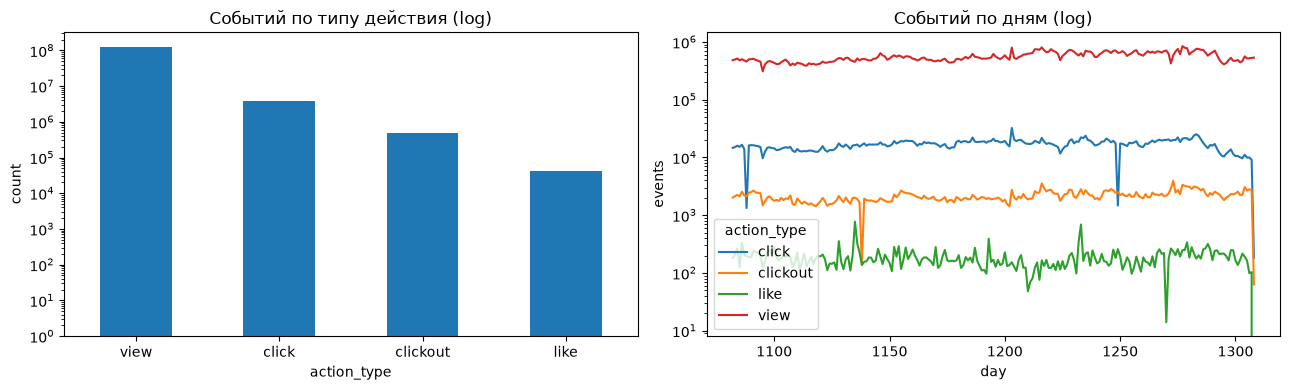

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

counts.plot(kind="bar", ax=axes[0], rot=0, log=True)
axes[0].set_title("Событий по типу действия (log)")
axes[0].set_ylabel("count")

# События по дням в разрезе типа действия
daily = df.groupby(["day", "action_type"], observed=True).size().unstack(fill_value=0)
daily.plot(ax=axes[1], logy=True)
axes[1].set_title("Событий по дням (log)")
axes[1].set_ylabel("events")

plt.tight_layout()
plt.show()

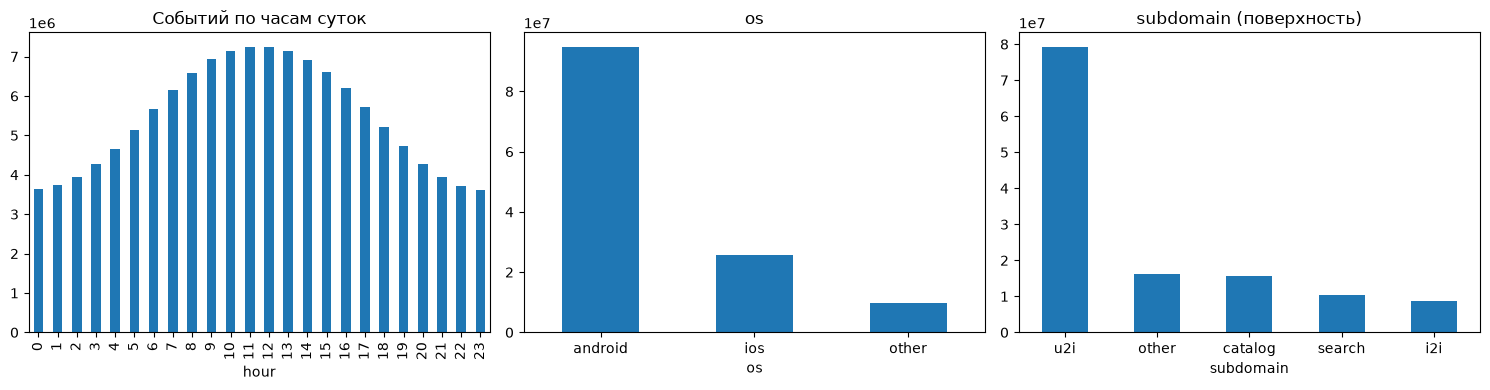

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["hour"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Событий по часам суток")

df["os"].value_counts().plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("os")

df["subdomain"].value_counts().plot(kind="bar", ax=axes[2], rot=0)
axes[2].set_title("subdomain (поверхность)")

plt.tight_layout()
plt.show()

In [5]:
# Доля кликов (tap) в событиях по поверхностям — где показ лучше всего конвертится
cross = df.pivot_table(
    index="subdomain", columns="action_type",
    values="item_id", aggfunc="size", fill_value=0, observed=True,
)
cross = cross.div(cross.sum(axis=1), axis=0).sort_values("click", ascending=False)
cross.round(3)

action_type,click,clickout,view
subdomain,,,
search,0.052,0.016,0.932
i2i,0.043,0.005,0.952
catalog,0.038,0.006,0.955
u2i,0.027,0.001,0.972
other,0.008,0.005,0.987


**Анализ**
- Классический дисбаланс воронки: на один click приходится ~33 view, clickout — ещё в ~8 раз реже.
- По поверхностям лучше всего в клик конвертятся `search` (~5.2%) и `i2i` (~4.3%), далее `catalog` (~3.8%); персональные рекомендации `u2i` — ~2.7%.
- Трафик почти целиком с Android, пики активности вечером.
- Данные обрезаны по дню — на последнем дне событий меньше.

## 2. Пользователи

Агрегируем события до профиля пользователя: активность и конверсия seen→tap.
Название `df_user_agg` — чтобы **не затирать** справочник `df_users` (кластер/регион пригодятся дальше).

In [6]:
# Действия каждого типа на пользователя
act = df.pivot_table(
    index="user_id", columns="action_type",
    values="item_id", aggfunc="size", fill_value=0, observed=True,
)
for a in ["view", "click", "clickout", "like"]:
    if a not in act:
        act[a] = 0

df_user_agg = (
    df.groupby("user_id")
    .agg(events=("item_id", "size"), unique_items=("item_id", "nunique"), active_days=("day", "nunique"))
    .join(act)
    .reset_index()
)
df_user_agg["click_rate"] = df_user_agg["click"] / df_user_agg["view"].replace(0, np.nan)

for c in ["events", "unique_items", "active_days", "view", "click", "clickout", "like"]:
    df_user_agg[c] = df_user_agg[c].astype(int)

print("users:", df_user_agg.shape[0])
df_user_agg.describe().round(2).T

users: 1616763


,count,mean,std,min,25%,50%,75%,max
user_id,1616763.0,44971715.92,25967219.37,3.0,22505816.5,44953047.0,67474267.00,89918702.0
events,1616763.0,80.68,160.01,1.0,9.0,28.0,79.00,2545.0
unique_items,1616763.0,53.28,97.27,1.0,8.0,22.0,56.00,1866.0
active_days,1616763.0,9.52,15.47,1.0,2.0,5.0,11.00,226.0
click,1616763.0,2.33,6.64,0.0,0.0,0.0,2.00,379.0
clickout,1616763.0,0.30,1.65,0.0,0.0,0.0,0.00,202.0
like,1616763.0,0.03,1.17,0.0,0.0,0.0,0.00,1151.0
view,1616763.0,78.02,154.33,0.0,9.0,28.0,77.00,2482.0
click_rate,1615380.0,0.02,0.06,0.0,0.0,0.0,0.03,11.5


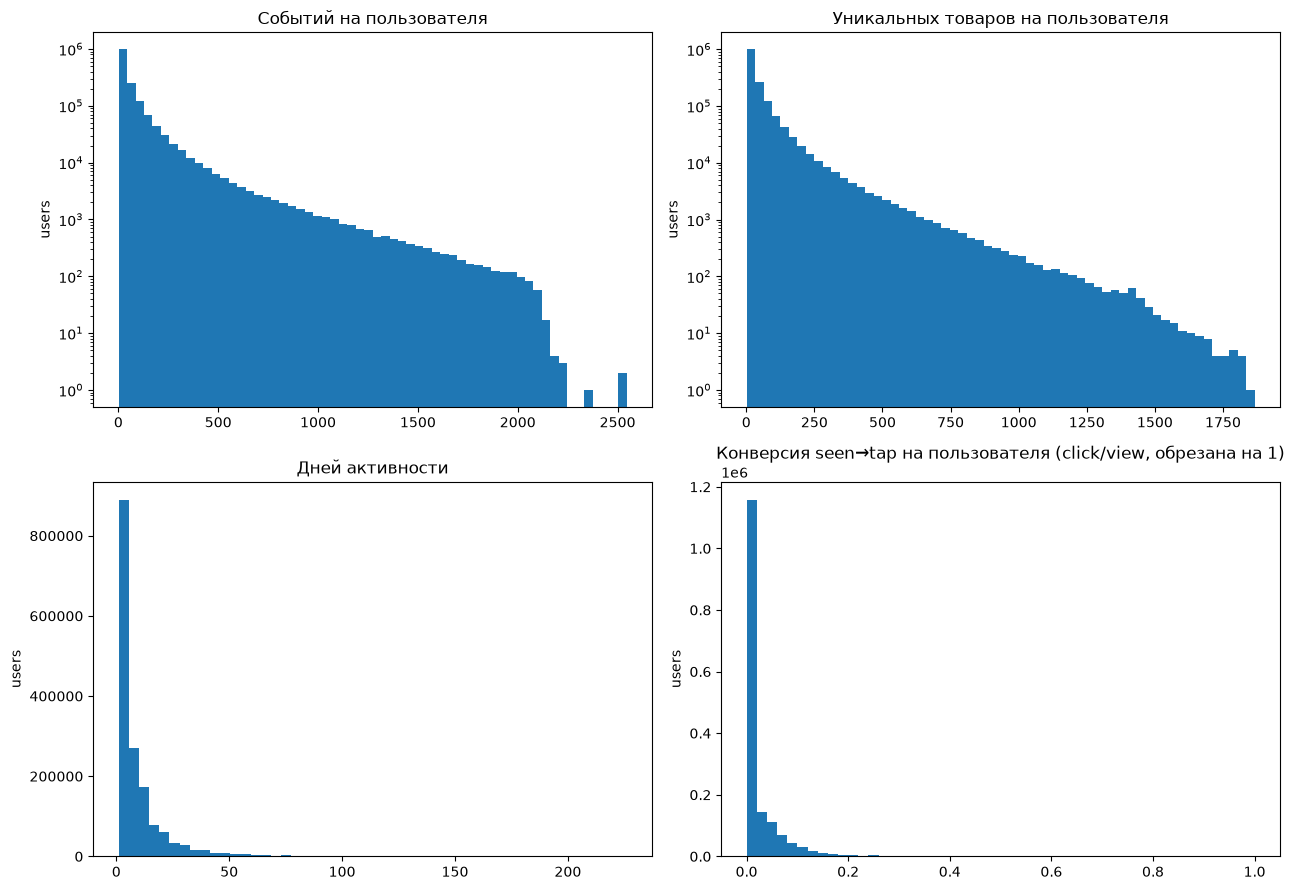

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].hist(df_user_agg["events"], bins=60, log=True)
axes[0, 0].set_title("Событий на пользователя")
axes[0, 1].hist(df_user_agg["unique_items"], bins=60, log=True)
axes[0, 1].set_title("Уникальных товаров на пользователя")
axes[1, 0].hist(df_user_agg["active_days"], bins=50)
axes[1, 0].set_title("Дней активности")
axes[1, 1].hist(df_user_agg["click_rate"].clip(upper=1).dropna(), bins=50)
axes[1, 1].set_title("Конверсия seen→tap на пользователя (click/view, обрезана на 1)")

for ax in axes.flat:
    ax.set_ylabel("users")
plt.tight_layout()
plt.show()

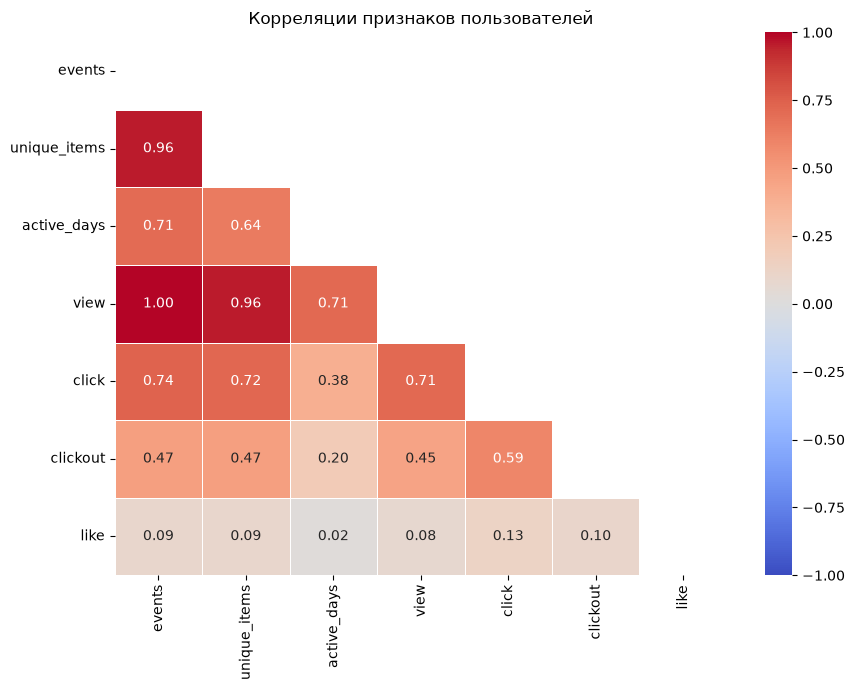

In [8]:
# Корреляции числовых признаков пользователя
cols = ["events", "unique_items", "active_days", "view", "click", "clickout", "like"]
corr = df_user_agg[cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True,
            cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Корреляции признаков пользователей")
plt.tight_layout()
plt.show()

**Анализ**
- Данные сильно перекошены: большинство из 1.6 млн пользователей заходят 1–5 дней и почти не кликают; медиана — 28 событий и 0 кликов.
- `view` и `events` коррелируют почти идеально (≈1.0) — события в основном и есть показы.
- Чем больше пользователь смотрит, тем больше уникальных товаров видит (r≈0.97) — не «зацикливается» на одних товарах.
- `like` почти ни с чем не коррелирует — слишком редкое событие, как признак слабое.
- Click rate у отдельных пользователей > 1 (кликов больше, чем показов): клик может случиться без logged view (например, из поиска). Это не «битые» пользователи, но при расчёте конверсий их стоит учитывать.

In [9]:
# Предлагаемый препроцессинг пользователей:
# 1) убрать click_rate > 1 (технические артефакты), 2) отрезать топ-1% по активности (боты/парсеры)
p99 = df_user_agg[["events", "unique_items", "active_days"]].quantile(0.99)
print("пороги p99:", p99.to_dict())

df_user_clean = df_user_agg[
    (df_user_agg["click_rate"].isna() | (df_user_agg["click_rate"] <= 1))
    & (df_user_agg["events"] <= p99["events"])
    & (df_user_agg["unique_items"] <= p99["unique_items"])
    & (df_user_agg["active_days"] <= p99["active_days"])
]
print(f"пользователей: {len(df_user_agg):,} -> {len(df_user_clean):,} "
      f"(удалено {1 - len(df_user_clean) / len(df_user_agg):.1%})")

пороги p99: {'events': 841.0, 'unique_items': 494.0, 'active_days': 73.0}
пользователей: 1,616,763 -> 1,586,675 (удалено 1.9%)


## 3. Соцдем-кластеры и регионы

В `users.pq` есть `socdem_cluster` — готовая сегментация аудитории.
Если кластеры по-разному ведут себя, персонализация «топ-товаров по кластеру» уже даст прибавку — это и проверим бейзлайном.

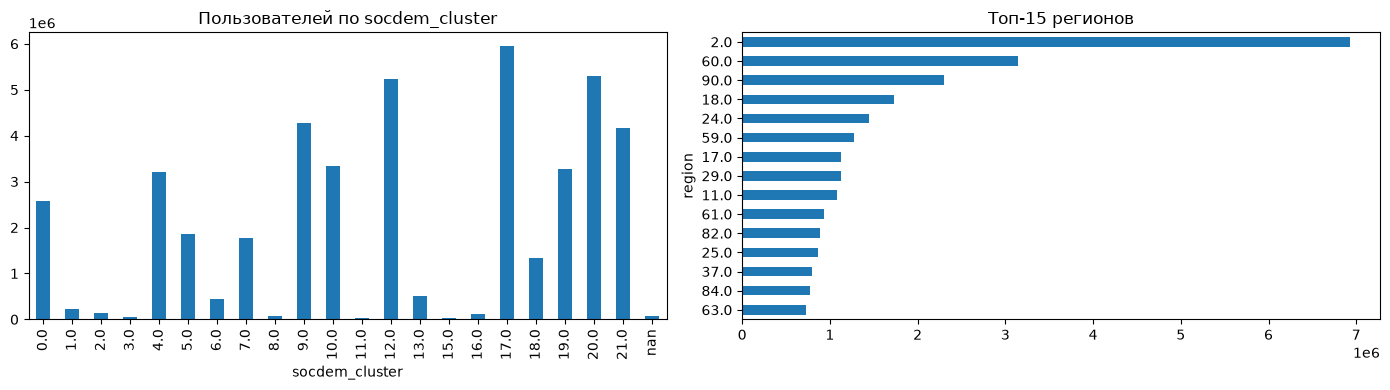

доля NaN кластера: 0.0015


In [10]:
# Распределение пользователей по кластерам и регионам
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df_users["socdem_cluster"].value_counts(dropna=False).sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Пользователей по socdem_cluster")

df_users["region"].value_counts().head(15).plot(kind="barh", ax=axes[1])
axes[1].invert_yaxis()
axes[1].set_title("Топ-15 регионов")

plt.tight_layout()
plt.show()

print("доля NaN кластера:", df_users["socdem_cluster"].isna().mean().round(4))

In [11]:
# Поведение по кластерам: активность и конверсия seen→tap
prof = df_user_agg.merge(df_users, on="user_id", how="left")

cluster_prof = (
    prof.groupby("socdem_cluster")
    .agg(
        users=("user_id", "size"),
        events_med=("events", "median"),
        active_days_med=("active_days", "median"),
        click_rate_med=("click_rate", "median"),
        click_rate_mean=("click_rate", "mean"),
    )
    .round(3)
)
cluster_prof

,users,events_med,active_days_med,click_rate_med,click_rate_mean
socdem_cluster,,,,,
0.0,93423,28.0,5.0,0.0,0.018
1.0,3946,18.0,3.0,0.0,0.019
2.0,2738,16.0,3.0,0.0,0.020
3.0,495,8.0,2.0,0.0,0.012
4.0,137031,37.0,6.0,0.0,0.021
5.0,83087,23.0,4.0,0.0,0.029
6.0,2894,4.0,1.0,0.0,0.007
7.0,73648,35.0,5.5,0.0,0.020
8.0,1992,27.5,4.0,0.0,0.019


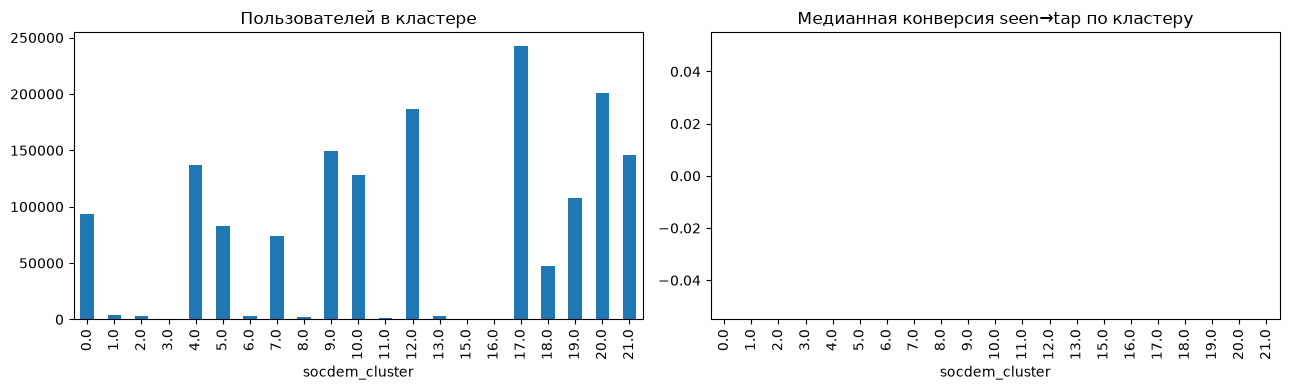

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

cluster_prof["users"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Пользователей в кластере")

cluster_prof["click_rate_med"].plot(kind="bar", ax=axes[1], color="tab:orange")
axes[1].set_title("Медианная конверсия seen→tap по кластеру")

plt.tight_layout()
plt.show()

**Анализ**
- Кластеры заметно различаются и по размеру (от 0.5 тыс. до 243 тыс. пользователей), и по поведению: средняя конверсия seen→tap — от 0.3% до 2.9% (в 10 раз), медианная активность — от 4 до 37 событий.
- Значит «один топ для всех» не оптимален: у сегментов разные интересы и кликабельность.
- NaN-кластер у ~0.15% пользователей — на них персонализацию по кластеру просто заменяем глобальным топом.

## 4. Товары

Ключевой вопрос для бейзлайна: как связаны **популярность** (сколько показов) и **конверсия seen→tap**?
Сырой click/view у редких товаров шумит (1 показ — 1 клик = 100%), поэтому при ранжировании понадобится сглаживание.

In [13]:
# Агрегаты по товару + конверсия
act_i = df.pivot_table(
    index="item_id", columns="action_type",
    values="user_id", aggfunc="size", fill_value=0, observed=True,
)
for a in ["view", "click", "clickout", "like"]:
    if a not in act_i:
        act_i[a] = 0

df_item_agg = (
    df.groupby("item_id", observed=True)
    .agg(events=("user_id", "size"), unique_users=("user_id", "nunique"))
    .join(act_i)
    .reset_index()
)
df_item_agg["click_rate"] = df_item_agg["click"] / df_item_agg["view"].replace(0, np.nan)

for c in ["events", "unique_users", "view", "click", "clickout", "like"]:
    df_item_agg[c] = df_item_agg[c].astype("int64")

print("items:", df_item_agg.shape[0])
df_item_agg.describe().round(2).T

items: 2325409


,count,mean,std,min,25%,50%,75%,max
events,2325409.0,56.10,2767.97,1.0,1.0,2.0,7.0,1346072.0
unique_users,2325409.0,37.04,1353.83,1.0,1.0,2.0,5.0,524759.0
click,2325409.0,1.62,95.75,0.0,0.0,0.0,0.0,68224.0
clickout,2325409.0,0.21,9.17,0.0,0.0,0.0,0.0,5517.0
like,2325409.0,0.02,0.65,0.0,0.0,0.0,0.0,439.0
view,2325409.0,54.25,2669.22,0.0,1.0,2.0,6.0,1271892.0
click_rate,2299405.0,0.04,0.15,0.0,0.0,0.0,0.0,19.0


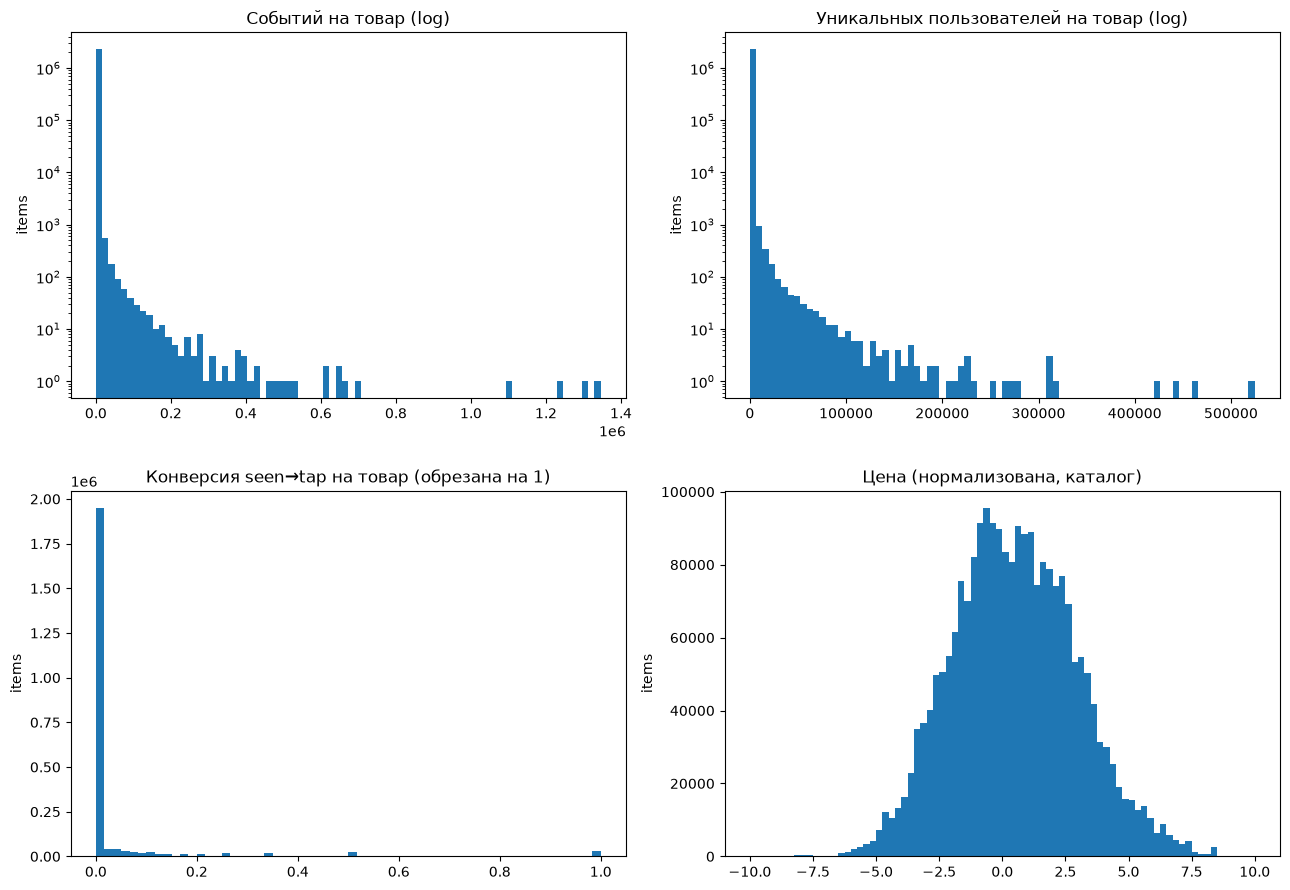

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].hist(df_item_agg["events"], bins=80, log=True)
axes[0, 0].set_title("Событий на товар (log)")
axes[0, 1].hist(df_item_agg["unique_users"], bins=80, log=True)
axes[0, 1].set_title("Уникальных пользователей на товар (log)")
axes[1, 0].hist(df_item_agg["click_rate"].clip(upper=1).dropna(), bins=60)
axes[1, 0].set_title("Конверсия seen→tap на товар (обрезана на 1)")
axes[1, 1].hist(df_items["price"].dropna(), bins=80)
axes[1, 1].set_title("Цена (нормализована, каталог)")

for ax in axes.flat:
    ax.set_ylabel("items")
plt.tight_layout()
plt.show()

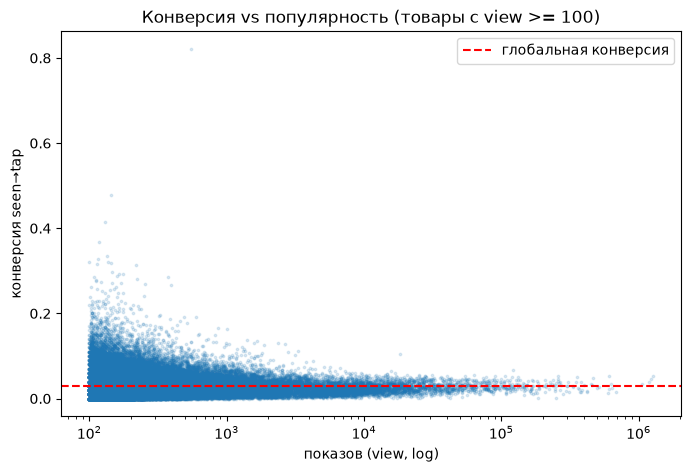

In [15]:
# Популярность vs конверсия: почему нужно сглаживание
pop = df_item_agg[df_item_agg["view"] >= 100]  # только товары со сколько-нибудь заметным показом

plt.figure(figsize=(8, 5))
plt.scatter(pop["view"], pop["click_rate"], s=3, alpha=0.15)
plt.xscale("log")
plt.axhline(df["action_type"].eq("click").sum() / df["action_type"].eq("view").sum(),
            color="red", ls="--", label="глобальная конверсия")
plt.xlabel("показов (view, log)")
plt.ylabel("конверсия seen→tap")
plt.title("Конверсия vs популярность (товары с view >= 100)")
plt.legend()
plt.show()

In [16]:
# Топ-10 товаров: по популярности и по конверсии (со сглаживанием CTR Лапласа)
glob_ctr = df_item_agg["click"].sum() / df_item_agg["view"].sum()
df_item_agg["ctr_smooth"] = (df_item_agg["click"] + 10 * glob_ctr) / (df_item_agg["view"] + 10)

cols = ["item_id", "view", "click", "click_rate", "ctr_smooth"]
top_pop = df_item_agg.nlargest(10, "view")[cols]
top_conv = df_item_agg[df_item_agg["view"] >= 1000].nlargest(10, "ctr_smooth")[cols]
display(top_pop, top_conv)

,item_id,view,click,click_rate,ctr_smooth
2000694,nfmcg_6396015,1271892,68224,0.053640,0.053640
2217260,nfmcg_8797298,1239419,57100,0.046070,0.046070
731222,nfmcg_18106422,1186847,47490,0.040014,0.040013
2084752,nfmcg_7326721,1061895,35569,0.033496,0.033496
597165,nfmcg_16621063,681771,9813,0.014393,0.014394
2232087,nfmcg_8961427,642208,16328,0.025425,0.025425
1568483,nfmcg_27366316,625020,20977,0.033562,0.033562
844012,nfmcg_19353812,607975,13703,0.022539,0.022539
2231767,nfmcg_8957656,606163,31508,0.051979,0.051979
800350,nfmcg_1887189,598732,7431,0.012411,0.012412


,item_id,view,click,click_rate,ctr_smooth
1721191,nfmcg_3295910,1000,163,0.163000,0.161682
1770696,nfmcg_3846938,1405,194,0.138078,0.137314
1747029,nfmcg_3582472,1654,222,0.134220,0.133593
1413768,nfmcg_25659588,2354,305,0.129567,0.129145
1274194,nfmcg_24115740,1583,205,0.129501,0.128876
2058700,nfmcg_7040596,2659,339,0.127492,0.127126
708922,nfmcg_17860060,1047,134,0.127985,0.127057
1908981,nfmcg_5378462,1872,235,0.125534,0.125026
1278871,nfmcg_24167834,1302,159,0.122120,0.121417
1023023,nfmcg_21335332,1331,156,0.117205,0.116554


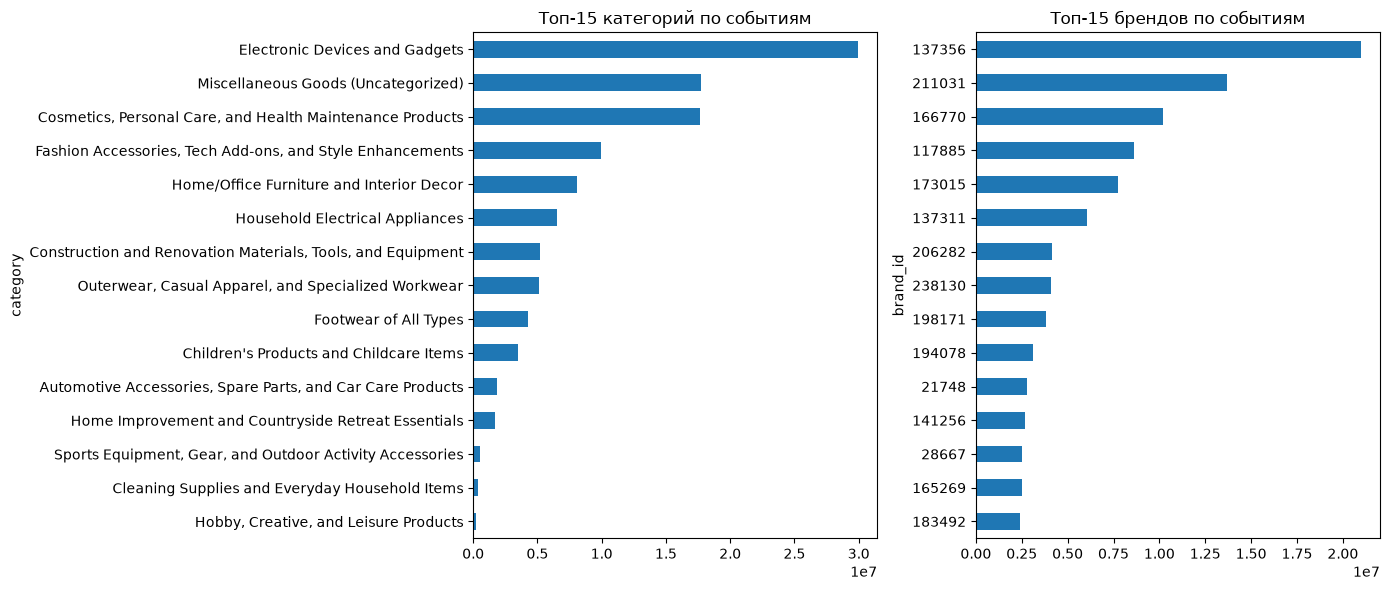

In [17]:
# Топ категорий и брендов по событиям
item_with_cat = df_item_agg.merge(
    df_items[["item_id", "category"]], on="item_id", how="left"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

item_with_cat.groupby("category")["events"].sum().nlargest(15).plot(kind="barh", ax=axes[0])
axes[0].invert_yaxis()
axes[0].set_title("Топ-15 категорий по событиям")

df_item_agg.merge(df_items[["item_id", "brand_id"]], on="item_id", how="left") \
    .groupby("brand_id")["events"].sum().nlargest(15).plot(kind="barh", ax=axes[1])
axes[1].invert_yaxis()
axes[1].set_title("Топ-15 брендов по событиям")

plt.tight_layout()
plt.show()

**Анализ**
- Экстремальные хвосты: у товаров-хитов >1 млн событий, у длинного хвоста — единицы. Много «холодных» товаров.
- Популярность и конверсия — разные вещи: топ по показам не совпадает с топом по конверсии.
- У редких товаров конверсия шумит (виден веер точек до 1.0) → при ранжировании считаем сглаженный CTR.
- Категория/подкатегория заполнены лишь частично (~42% / ~53% пропусков), цена уже нормализована.
- Электроника — лидер по трафику, далее косметика и uncategorized.

## 5. Пропуски

In [18]:
def missing_report(frame: pd.DataFrame, name: str = "") -> None:
    miss = frame.isna().sum()
    miss = miss[miss > 0].sort_values(ascending=False)
    print(f"=== {name}: строк {len(frame):,}, пропусков {frame.isna().sum().sum():,} ===")
    if miss.empty:
        print("пропусков нет\n")
        return
    print(pd.DataFrame({"missing": miss, "share_%": (miss / len(frame) * 100).round(2)}), "\n")

missing_report(df, "df (events)")
missing_report(df_items, "df_items (каталог)")
missing_report(df_users, "df_users (справочник)")

=== df (events): строк 130,447,117, пропусков 41,792 ===
           missing  share_%
subdomain    41792     0.03 



=== df_items (каталог): строк 2,325,409, пропусков 2,202,373 ===
             missing  share_%
subcategory  1233023    53.02
category      966395    41.56
price           2882     0.12
embedding         73     0.00 



=== df_users (справочник): строк 43,997,878, пропусков 804,299 ===
                missing  share_%
region           739734     1.68
socdem_cluster    64565     0.15 



## Выводы для моделирования

1. **Целевое событие** — click (tap) после показа (seen): глобальная конверсия ~3%. Классы сильно несбалансированы.
2. **Популярность ≠ конверсия**: топ по показам и топ по CTR — разные товары. Для бейзлайна ранжируем по сглаженной конверсии `(click + α·CTR) / (view + α)`.
3. **Соцдем-кластеры различаются поведением** (активность и конверсия в разы) → имеет смысл персонализировать топ по кластеру; NaN-кластеру отдаём глобальный топ.
4. **Хвосты и выбросы**:резать топ-1% пользователей (боты) и не доверять конверсии товаров с малым числом показов.
5. **Для сервиса объяснений** в каталоге есть категория/бренд/цена — их хватит, чтобы объяснять «популярно в вашем сегменте».
6. **Время**: события обрезаны по дню; при временно́м сплите учитываем правило T-ECD — последние 12 часов не использовать.